# 03. Modelos baseline — contratos de obra (snapshots point-in-time)

Este notebook implementa os primeiros modelos baseline sobre `dataset_modelagem_obras_snapshots.csv` ou `dataset_modelagem_obras_snapshots_v2.csv`.

Objetivos:

1. **Regressão:** estimar `target_dias_atraso`, isto é, quantos dias de atraso haverá na conclusão da obra.
2. **Classificação:** estimar `target_atraso` e sua probabilidade.

Princípios metodológicos adotados:

- usa somente snapshots com `flag_apto_treino = 1`;
- respeita o `split_modelagem` temporal definido no nível do contrato;
- nunca mistura snapshots do mesmo contrato entre treino, validação e teste;
- usa `sample_weight_contrato` para reduzir o excesso de peso de contratos com muitos snapshots;
- exclui identificadores, targets e campos `_controle` das features;
- para **classificação**, a avaliação principal usa apenas snapshots **antes do vencimento do prazo vigente** (`dias_restantes_prazo_vigente >= 0`), pois após o prazo a ocorrência de atraso já é praticamente conhecida;
- reporta métricas apropriadas ao desbalanceamento e à calibração de probabilidades.

> O objetivo é criar referências simples, reproduzíveis e difíceis de “enganar” por leakage. Modelos mais complexos devem ser comparados contra estes resultados.


**Compatibilidade:** se `sample_weight_contrato` e/ou `split_modelagem` não existirem (caso da V1), o notebook os cria automaticamente antes da modelagem.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 1. Carregamento e validação do dataset

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

for folder in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Aceita tanto a V2 enriquecida quanto a V1 original.
candidate_paths = [
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots_v2.csv",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots_v2.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots.csv",
    Path("/mnt/data/dataset_modelagem_obras_snapshots_v2.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots.csv"),
]

DATASET_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Nenhum dataset de snapshots foi encontrado. "
        "Esperado: dataset_modelagem_obras_snapshots.csv ou "
        "dataset_modelagem_obras_snapshots_v2.csv."
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)

for c in [
    "data_corte",
    "data_os",
    "data_termino_original",
    "data_termino_vigente_corte",
    "data_conclusao_controle",
    "data_termino_vigente_final_controle",
]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# ------------------------------------------------------------------
# Validação mínima: apenas colunas que existem tanto na V1 quanto na V2
# ------------------------------------------------------------------
required_base = [
    "id_contrato",
    "data_corte",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "dias_restantes_prazo_vigente",
    "data_conclusao_controle",
]

missing_base = [c for c in required_base if c not in df.columns]
if missing_base:
    raise ValueError(f"Colunas obrigatórias realmente ausentes: {missing_base}")

# ------------------------------------------------------------------
# Compatibilidade V1 -> cria pesos por contrato caso não existam
# ------------------------------------------------------------------
if "sample_weight_contrato" not in df.columns:
    counts = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")
        .size()
    )

    df["sample_weight_contrato_raw"] = df["id_contrato"].map(
        lambda cid: 1.0 / counts[cid] if cid in counts.index else np.nan
    )

    mean_w = df.loc[
        df["flag_apto_treino"].eq(1),
        "sample_weight_contrato_raw"
    ].mean()

    df["sample_weight_contrato"] = (
        df["sample_weight_contrato_raw"] / mean_w
    )

    print("Criado automaticamente: sample_weight_contrato")
else:
    print("Usando sample_weight_contrato existente no dataset.")

# ------------------------------------------------------------------
# Compatibilidade V1 -> cria split temporal no nível do contrato
# ------------------------------------------------------------------
if "split_modelagem" not in df.columns:
    contratos_rotulados = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")["data_conclusao_controle"]
        .max()
        .dropna()
        .sort_values()
    )

    n = len(contratos_rotulados)
    n_train = int(np.floor(n * 0.70))
    n_val = int(np.floor(n * 0.15))

    ids_train = set(contratos_rotulados.index[:n_train])
    ids_val = set(contratos_rotulados.index[n_train:n_train + n_val])
    ids_test = set(contratos_rotulados.index[n_train + n_val:])

    df["split_contrato_temporal"] = "scoring"
    df.loc[df["id_contrato"].isin(ids_train), "split_contrato_temporal"] = "train"
    df.loc[df["id_contrato"].isin(ids_val), "split_contrato_temporal"] = "validation"
    df.loc[df["id_contrato"].isin(ids_test), "split_contrato_temporal"] = "test"

    df["split_modelagem"] = np.where(
        df["flag_apto_treino"].eq(1),
        df["split_contrato_temporal"],
        "nao_supervisionado"
    )

    print("Criado automaticamente: split_contrato_temporal")
    print("Criado automaticamente: split_modelagem")
else:
    print("Usando split_modelagem existente no dataset.")

# Se a V2 possuir apenas split_modelagem, reconstrói split_contrato_temporal
if "split_contrato_temporal" not in df.columns:
    contract_split = (
        df[df["split_modelagem"].isin(["train", "validation", "test"])]
        .drop_duplicates("id_contrato")
        .set_index("id_contrato")["split_modelagem"]
        .to_dict()
    )
    df["split_contrato_temporal"] = (
        df["id_contrato"].map(contract_split).fillna("scoring")
    )

print("\nArquivo:", DATASET_PATH)
print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())

display(
    df["split_modelagem"]
    .value_counts(dropna=False)
    .rename("snapshots")
    .to_frame()
)

display(
    df.loc[df["flag_apto_treino"].eq(1)]
    .groupby("split_modelagem")["id_contrato"]
    .nunique()
    .rename("contratos")
    .to_frame()
)


Criado automaticamente: sample_weight_contrato
Criado automaticamente: split_contrato_temporal
Criado automaticamente: split_modelagem

Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Shape: (1435, 47)
Contratos: 78


,snapshots
split_modelagem,
train,621
nao_supervisionado,401
test,261
validation,152


,contratos
split_modelagem,
test,10
train,41
validation,8


## 2. Amostras supervisionadas

A regressão usa todos os snapshots rotulados e anteriores à conclusão.

A classificação principal usa somente snapshots em que o prazo vigente **ainda não venceu**. Isso evita um atalho lógico: se a obra está aberta depois do prazo, já sabemos que houve atraso.


In [3]:
model_data = df[df["flag_apto_treino"].eq(1)].copy()

valid_splits = ["train", "validation", "test"]
model_data = model_data[model_data["split_modelagem"].isin(valid_splits)].copy()

reg_data = model_data.copy()
clf_data = model_data[model_data["dias_restantes_prazo_vigente"].ge(0)].copy()

summary = pd.DataFrame({
    "amostra": ["regressao", "classificacao_pre_prazo"],
    "snapshots": [len(reg_data), len(clf_data)],
    "contratos": [reg_data["id_contrato"].nunique(), clf_data["id_contrato"].nunique()],
    "taxa_atraso": [reg_data["target_atraso"].mean(), clf_data["target_atraso"].mean()],
    "mediana_dias_atraso": [reg_data["target_dias_atraso"].median(), clf_data["target_dias_atraso"].median()],
})
display(summary)

for split in valid_splits:
    r = reg_data[reg_data["split_modelagem"].eq(split)]
    c = clf_data[clf_data["split_modelagem"].eq(split)]
    print(
        f"{split:10s} | regressão: {len(r):4d} snapshots / {r.id_contrato.nunique():2d} contratos"
        f" | classificação pré-prazo: {len(c):4d} / {c.id_contrato.nunique():2d}"
    )

if clf_data["target_atraso"].nunique() < 2:
    raise ValueError("A amostra de classificação não possui as duas classes.")


,amostra,snapshots,contratos,taxa_atraso,mediana_dias_atraso
0,regressao,1034,59,0.8395,167.0000
1,classificacao_pre_prazo,720,59,0.7764,113.0000


train      | regressão:  621 snapshots / 41 contratos | classificação pré-prazo:  430 / 41
validation | regressão:  152 snapshots /  8 contratos | classificação pré-prazo:  102 /  8
test       | regressão:  261 snapshots / 10 contratos | classificação pré-prazo:  188 / 10


## 3. Features do baseline

**Não entram:** identificadores, datas finais, status final, targets, pesos, splits e qualquer coluna `_controle`.

O fornecedor também fica fora do baseline porque há poucos contratos por fornecedor e o identificador poderia favorecer memorização. Em uma etapa posterior, pode ser substituído por estatísticas históricas do fornecedor.


In [4]:
numeric_features = [
    # contrato / prazo
    "valor_total_contrato",
    "prazo_original_dias",
    "dias_desde_os",
    "dias_restantes_prazo_vigente",
    "pct_prazo_consumido",
    "qtd_aditivos_prazo",
    "dias_aditados_acumulados",
    "pct_dias_aditados_sobre_prazo_original",
    "qtd_aditivos_valor",

    # execução / parcelas
    "pct_parcelas_concluidas_vs_previstas",
    "atraso_medio_parcelas_dias",
    "atraso_maximo_parcelas_dias",
    "pct_parcelas_atrasadas",
    "recent_atraso_medio_parcelas_30d",
    "recent_atraso_medio_parcelas_90d",
    "recent_pct_parcelas_atrasadas_90d",
    "delta_atraso_90d_vs_historico",
    "dias_desde_ultima_parcela_concluida",

    # financeiro / liberações
    "pct_financeiro_liberado",
    "gap_prazo_financeiro",
    "recent_atraso_medio_liberacao_90d",
    "dias_desde_ultima_liberacao",

    # gaps e pressão
    "gap_prazo_execucao",
    "pressao_tempo_financeiro",
    "pressao_tempo_execucao",

    # sazonalidade
    "mes_sin",
    "mes_cos",
]

categorical_features = [
    "classificacao_contrato_agrupada",
]

numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]
features = numeric_features + categorical_features

print(f"{len(features)} features selecionadas")
print("Numéricas:", len(numeric_features))
print("Categóricas:", len(categorical_features))


14 features selecionadas
Numéricas: 14
Categóricas: 0


## 4. Preprocessamento

- numéricas: mediana do treino + padronização;
- categóricas: moda + one-hot;
- todo o ajuste ocorre dentro do `Pipeline`, portanto estatísticas do teste não entram no treino.


In [5]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)


# Parte A — Regressão baseline

Comparações:

1. **Dummy mediana:** prevê sempre a mediana ponderada observada no treino.
2. **Ridge:** baseline linear regularizado, mais estável que regressão linear pura diante da multicolinearidade.

Métricas:
- MAE;
- MedAE;
- RMSE;
- R²;
- percentual de previsões com erro absoluto ≤ 30 dias.

O conjunto de **validation** serve para comparação inicial. O **test** permanece como avaliação temporal final.


In [6]:
def split_xy(data, split):
    part = data[data["split_modelagem"].eq(split)].copy()
    X = part[features]
    y_reg = part["target_dias_atraso"].astype(float)
    y_clf = part["target_atraso"].astype(int)
    w = part["sample_weight_contrato"].astype(float)
    return part, X, y_reg, y_clf, w


reg_train, Xr_train, yr_train, _, wr_train = split_xy(reg_data, "train")
reg_val, Xr_val, yr_val, _, wr_val = split_xy(reg_data, "validation")
reg_test, Xr_test, yr_test, _, wr_test = split_xy(reg_data, "test")

regression_models = {
    "dummy_mediana": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "ridge": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", Ridge(alpha=10.0)),
    ]),
}


def regression_metrics(y_true, y_pred, sample_weight=None):
    return {
        "mae": mean_absolute_error(y_true, y_pred, sample_weight=sample_weight),
        "medae": median_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred, sample_weight=sample_weight) ** 0.5,
        "r2": r2_score(y_true, y_pred, sample_weight=sample_weight),
        "pct_erro_ate_30d": np.average(
            np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 30,
            weights=sample_weight,
        ),
        "erro_medio_assinado": np.average(
            np.asarray(y_pred) - np.asarray(y_true),
            weights=sample_weight,
        ),
    }


regression_results = []
fitted_regression = {}

for name, model in regression_models.items():
    model.fit(Xr_train, yr_train, model__sample_weight=wr_train)
    fitted_regression[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xr_val, yr_val, wr_val),
        ("test", Xr_test, yr_test, wr_test),
    ]:
        pred = np.maximum(0, model.predict(X_))
        row = {"modelo": name, "split": split_name}
        row.update(regression_metrics(y_, pred, w_))
        regression_results.append(row)

regression_metrics_df = pd.DataFrame(regression_results).sort_values(["split", "mae"])
display(regression_metrics_df)


,modelo,split,mae,medae,rmse,r2,pct_erro_ate_30d,erro_medio_assinado
3,ridge,test,116.8028,117.9017,153.7512,0.1546,0.1610,-24.8349
1,dummy_mediana,test,169.5000,136.0000,229.4387,-0.8827,0.0000,-157.1000
2,ridge,validation,89.6544,135.8871,160.5923,0.4560,0.3513,-1.0299
0,dummy_mediana,validation,143.2500,703.0000,256.4483,-0.3873,0.1250,-135.5000


In [7]:
# Previsões de regressão no teste
regression_predictions = reg_test[
    ["id_contrato", "data_corte", "faixa_antecedencia", "target_dias_atraso", "sample_weight_contrato"]
].copy()

for name, model in fitted_regression.items():
    regression_predictions[f"pred_{name}"] = np.maximum(0, model.predict(Xr_test))

display(regression_predictions.head(10))


,id_contrato,data_corte,faixa_antecedencia,target_dias_atraso,sample_weight_contrato,pred_dummy_mediana,pred_ridge
612,158,2021-09-23,>=180d,313.0000,0.3307,31.0000,30.3081
613,158,2021-09-30,>=180d,313.0000,0.3307,31.0000,34.5585
614,158,2021-10-31,>=180d,313.0000,0.3307,31.0000,0.0000
615,158,2021-11-30,>=180d,313.0000,0.3307,31.0000,60.6427
616,158,2021-12-31,>=180d,313.0000,0.3307,31.0000,79.2981
617,158,2022-01-31,>=180d,313.0000,0.3307,31.0000,100.3732
618,158,2022-02-28,>=180d,313.0000,0.3307,31.0000,102.2845
619,158,2022-03-31,>=180d,313.0000,0.3307,31.0000,120.8645
620,158,2022-04-30,>=180d,313.0000,0.3307,31.0000,140.1545
621,158,2022-05-31,>=180d,313.0000,0.3307,31.0000,155.8640


### Desempenho da regressão por antecedência

In [8]:
best_reg_name = (
    regression_metrics_df[regression_metrics_df["split"].eq("validation")]
    .sort_values("mae")
    .iloc[0]["modelo"]
)
best_reg = fitted_regression[best_reg_name]

reg_test_eval = reg_test.copy()
reg_test_eval["pred"] = np.maximum(0, best_reg.predict(Xr_test))
reg_test_eval["erro_abs"] = np.abs(
    reg_test_eval["target_dias_atraso"] - reg_test_eval["pred"]
)

horizon_metrics = (
    reg_test_eval.groupby("faixa_antecedencia", observed=True)
    .apply(lambda g: pd.Series({
        "snapshots": len(g),
        "contratos": g["id_contrato"].nunique(),
        "mae": np.average(g["erro_abs"], weights=g["sample_weight_contrato"]),
        "mediana_erro_abs": g["erro_abs"].median(),
    }))
    .reset_index()
)

display(horizon_metrics)


,faixa_antecedencia,snapshots,contratos,mae,mediana_erro_abs
0,30-89d,36.0000,10.0000,122.1214,151.4570
1,90-179d,24.0000,9.0000,113.0034,123.6697
2,<30d,108.0000,10.0000,128.3155,134.5504
3,>=180d,93.0000,6.0000,96.3061,105.6020


OBS: a diferença pode refletir mais a composição dos contratos do que propriamente a antecedência.

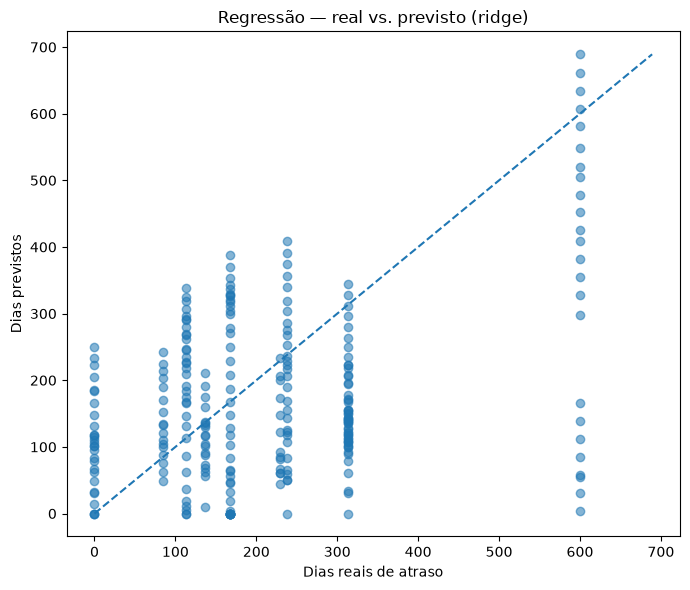

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(
    reg_test_eval["target_dias_atraso"],
    reg_test_eval["pred"],
    alpha=0.55,
)
mx = max(reg_test_eval["target_dias_atraso"].max(), reg_test_eval["pred"].max())
plt.plot([0, mx], [0, mx], linestyle="--")
plt.xlabel("Dias reais de atraso")
plt.ylabel("Dias previstos")
plt.title(f"Regressão — real vs. previsto ({best_reg_name})")
plt.tight_layout()
plt.show()


# Parte B — Classificação baseline

A avaliação principal é feita **antes do vencimento do prazo**.

Modelos:

1. **Dummy prior:** reproduz a prevalência observada no treino.
2. **Regressão logística:** baseline probabilístico principal, sem rebalanceamento artificial das classes.
3. **Regressão logística balanceada:** referência adicional para verificar o efeito de priorizar separação entre classes.

A logística padrão é a principal referência de **probabilidade**, pois `class_weight="balanced"` altera o peso relativo das classes e pode degradar a calibração.

Métricas:
- balanced accuracy;
- precision, recall e F1;
- ROC-AUC;
- **PR-AUC / Average Precision**;
- **Brier Score**, especialmente importante porque a probabilidade prevista será utilizada operacionalmente.


In [10]:
clf_train, Xc_train, _, yc_train, wc_train = split_xy(clf_data, "train")
clf_val, Xc_val, _, yc_val, wc_val = split_xy(clf_data, "validation")
clf_test, Xc_test, _, yc_test, wc_test = split_xy(clf_data, "test")

classification_models = {
    "dummy_prior": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "regressao_logistica": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
    "regressao_logistica_balanceada": Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
}


def classification_metrics(y_true, pred, proba, sample_weight=None):
    metrics = {
        "accuracy": accuracy_score(y_true, pred, sample_weight=sample_weight),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred, sample_weight=sample_weight),
        "precision": precision_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "recall": recall_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "f1": f1_score(y_true, pred, sample_weight=sample_weight, zero_division=0),
        "brier": brier_score_loss(y_true, proba, sample_weight=sample_weight),
    }
    if pd.Series(y_true).nunique() == 2:
        metrics["roc_auc"] = roc_auc_score(y_true, proba, sample_weight=sample_weight)
        metrics["pr_auc"] = average_precision_score(y_true, proba, sample_weight=sample_weight)
    else:
        metrics["roc_auc"] = np.nan
        metrics["pr_auc"] = np.nan
    return metrics


classification_results = []
fitted_classification = {}

for name, model in classification_models.items():
    model.fit(Xc_train, yc_train, model__sample_weight=wc_train)
    fitted_classification[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xc_val, yc_val, wc_val),
        ("test", Xc_test, yc_test, wc_test),
    ]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= 0.50).astype(int)

        row = {"modelo": name, "split": split_name, "threshold": 0.50}
        row.update(classification_metrics(y_, pred, proba, w_))
        classification_results.append(row)

classification_metrics_df = pd.DataFrame(classification_results)
display(classification_metrics_df.sort_values(["split", "brier"], ascending=[True, True]))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
1,dummy_prior,test,0.5000,0.7296,0.5000,0.7296,1.0000,0.8437,0.2171,0.5000,0.7296
3,regressao_logistica,test,0.5000,0.5125,0.4102,0.6777,0.6329,0.6545,0.3383,0.3715,0.6920
5,regressao_logistica_balanceada,test,0.5000,0.4538,0.3765,0.6500,0.5447,0.5927,0.3591,0.3724,0.6925
0,dummy_prior,validation,0.5000,0.8085,0.5000,0.8085,1.0000,0.8941,0.2031,0.5000,0.8085
2,regressao_logistica,validation,0.5000,0.7841,0.6610,0.8709,0.8605,0.8656,0.2065,0.7342,0.9281
4,regressao_logistica_balanceada,validation,0.5000,0.6409,0.6605,0.8961,0.6287,0.7390,0.2426,0.7298,0.9263


## 5. Threshold escolhido na validação

A probabilidade prevista é a saída principal. O threshold serve apenas para converter risco em decisão binária.

O threshold é ajustado **somente na validação** usando a regressão logística padrão e depois congelado para o teste. Como referência simples, escolhemos o ponto que maximiza F1 ponderado por contrato.

> Em produção, o threshold deveria refletir o custo de falso positivo e falso negativo, e não apenas uma métrica estatística.


In [11]:
probability_model_name = "regressao_logistica"
logit = fitted_classification[probability_model_name]
val_proba = logit.predict_proba(Xc_val)[:, 1]

threshold_grid = np.arange(0.10, 0.91, 0.02)
threshold_rows = []

for threshold in threshold_grid:
    pred = (val_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "f1": f1_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(yc_val, pred, sample_weight=wc_val),
        "precision": precision_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
        "recall": recall_score(yc_val, pred, sample_weight=wc_val, zero_division=0),
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_table.sort_values(["f1", "balanced_accuracy"], ascending=False).iloc[0]["threshold"]
)

print(f"Modelo probabilístico: {probability_model_name}")
print(f"Threshold escolhido na validação: {best_threshold:.2f}")
display(
    threshold_table.sort_values(["f1", "balanced_accuracy"], ascending=False).head(10)
)


Modelo probabilístico: regressao_logistica
Threshold escolhido na validação: 0.52


,threshold,f1,balanced_accuracy,precision,recall
21,0.5200,0.8737,0.6995,0.8873,0.8605
0,0.1000,0.8728,0.4789,0.8017,0.9578
1,0.1200,0.8685,0.4747,0.8003,0.9495
2,0.1400,0.8671,0.4734,0.7999,0.9467
3,0.1600,0.8671,0.4734,0.7999,0.9467
17,0.4400,0.8663,0.5986,0.8443,0.8895
4,0.1800,0.8657,0.4720,0.7994,0.9440
5,0.2000,0.8657,0.4720,0.7994,0.9440
6,0.2200,0.8657,0.4720,0.7994,0.9440
19,0.4800,0.8656,0.6610,0.8709,0.8605


In [12]:
test_proba = logit.predict_proba(Xc_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

final_classification_metrics = {
    "modelo": probability_model_name,
    "split": "test",
    "threshold": best_threshold,
    **classification_metrics(yc_test, test_pred, test_proba, wc_test),
}
display(pd.DataFrame([final_classification_metrics]))

classification_predictions = clf_test[
    ["id_contrato", "data_corte", "dias_restantes_prazo_vigente",
     "faixa_antecedencia", "target_atraso", "sample_weight_contrato"]
].copy()
classification_predictions["prob_atraso"] = test_proba
classification_predictions["pred_atraso"] = test_pred

display(classification_predictions.head(10))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,regressao_logistica,test,0.5200,0.5052,0.4052,0.6741,0.6229,0.6475,0.3383,0.3715,0.6920


,id_contrato,data_corte,dias_restantes_prazo_vigente,faixa_antecedencia,target_atraso,sample_weight_contrato,prob_atraso,pred_atraso
612,158,2021-09-23,450,>=180d,1.0000,0.3307,0.3591,0
613,158,2021-09-30,443,>=180d,1.0000,0.3307,0.3750,0
614,158,2021-10-31,412,>=180d,1.0000,0.3307,0.3717,0
615,158,2021-11-30,382,>=180d,1.0000,0.3307,0.5095,0
616,158,2021-12-31,351,>=180d,1.0000,0.3307,0.5734,1
617,158,2022-01-31,320,>=180d,1.0000,0.3307,0.3821,0
618,158,2022-02-28,329,>=180d,1.0000,0.3307,0.2923,0
619,158,2022-03-31,298,>=180d,1.0000,0.3307,0.3580,0
620,158,2022-04-30,268,>=180d,1.0000,0.3307,0.3726,0
621,158,2022-05-31,237,>=180d,1.0000,0.3307,0.4376,0


### Avaliação complementar por contrato em horizonte aproximadamente fixo

Métricas por snapshot ainda contêm várias observações da mesma obra. Como diagnóstico complementar, selecionamos **um snapshot por contrato**, o mais próximo de 90 dias antes do prazo vigente, e calculamos as métricas sem pesos.

In [13]:
contract_eval = classification_predictions.copy()
contract_eval["dist_90d"] = (
    contract_eval["dias_restantes_prazo_vigente"] - 90
).abs()

contract_eval = (
    contract_eval.sort_values(["id_contrato", "dist_90d", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .first()
)

if contract_eval["target_atraso"].nunique() == 2:
    contract_level_metrics = pd.DataFrame([{
        "horizonte_referencia_dias": 90,
        "contratos": len(contract_eval),
        **classification_metrics(
            contract_eval["target_atraso"].astype(int),
            contract_eval["pred_atraso"].astype(int),
            contract_eval["prob_atraso"],
            sample_weight=None,
        ),
    }])
else:
    contract_level_metrics = pd.DataFrame([{
        "horizonte_referencia_dias": 90,
        "contratos": len(contract_eval),
        "observacao": "Apenas uma classe presente neste recorte; AUC não calculável.",
    }])

display(contract_eval[
    ["id_contrato", "data_corte", "dias_restantes_prazo_vigente",
     "target_atraso", "prob_atraso", "pred_atraso"]
])
display(contract_level_metrics)


,id_contrato,data_corte,dias_restantes_prazo_vigente,target_atraso,prob_atraso,pred_atraso
0,158,2022-10-31,91,1.0000,0.2540,0
1,173,2024-07-31,80,1.0000,0.9979,1
2,201,2024-11-30,102,1.0000,0.6509,1
3,205,2024-09-30,86,1.0000,0.8459,1
4,248,2023-12-31,89,1.0000,0.6058,1
5,254,2025-05-31,83,0.0000,0.9694,1
6,283,2024-11-30,97,1.0000,0.6246,1
7,317,2024-11-30,84,1.0000,0.6243,1
8,342,2025-07-18,60,0.0000,0.6320,1
9,377,2025-04-29,90,1.0000,0.6133,1


,horizonte_referencia_dias,contratos,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,90,10,0.7000,0.4375,0.7778,0.8750,0.8235,0.2628,0.2500,0.7657


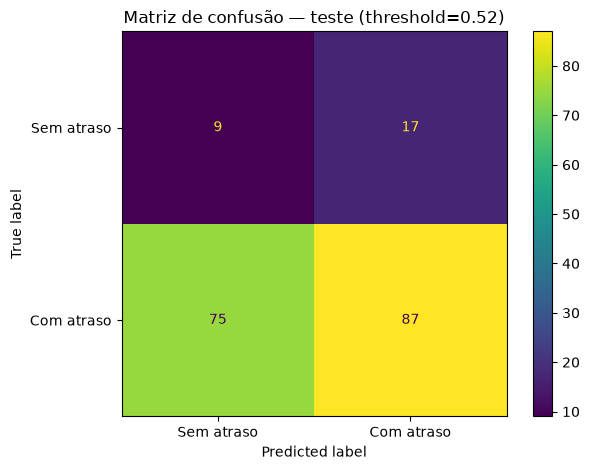

              precision    recall  f1-score   support

  Sem atraso       0.11      0.35      0.16        26
  Com atraso       0.84      0.54      0.65       162

    accuracy                           0.51       188
   macro avg       0.47      0.44      0.41       188
weighted avg       0.74      0.51      0.59       188



In [14]:
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    test_pred,
    display_labels=["Sem atraso", "Com atraso"],
    values_format="d",
)
plt.title(f"Matriz de confusão — teste (threshold={best_threshold:.2f})")
plt.tight_layout()
plt.show()

print(classification_report(
    yc_test,
    test_pred,
    target_names=["Sem atraso", "Com atraso"],
    zero_division=0,
))


## 6. Calibração das probabilidades

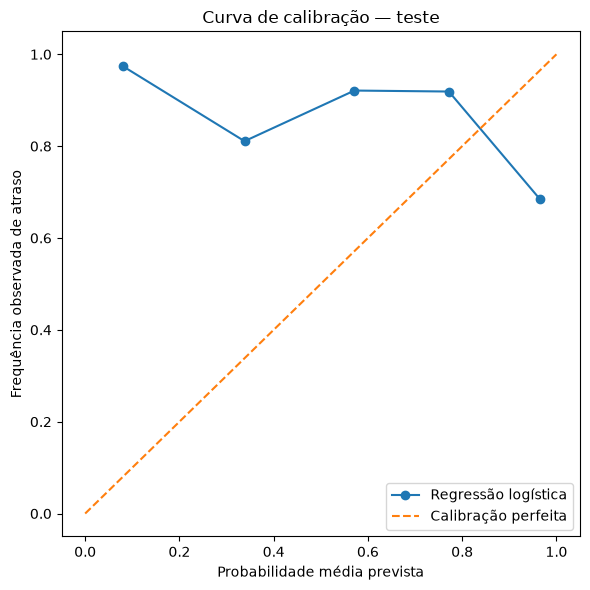

In [15]:
if pd.Series(yc_test).nunique() == 2:
    prob_true, prob_pred = calibration_curve(
        yc_test,
        test_proba,
        n_bins=5,
        strategy="quantile",
    )

    plt.figure(figsize=(6, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Regressão logística")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
    plt.xlabel("Probabilidade média prevista")
    plt.ylabel("Frequência observada de atraso")
    plt.title("Curva de calibração — teste")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 7. Coeficientes da regressão logística

Os coeficientes abaixo são da **regressão logística padrão**, usada como baseline probabilístico. Eles representam associações dentro do modelo linear, não efeitos causais. Como as features numéricas são padronizadas, a magnitude é aproximadamente comparável entre elas.


In [16]:
feature_names = logit.named_steps["preprocessing"].get_feature_names_out()
coefficients = logit.named_steps["model"].coef_[0]

coefficient_table = (
    pd.DataFrame({
        "caracteristica": feature_names,
        "coeficiente": coefficients,
        "efeito_absoluto": np.abs(coefficients),
    })
    .sort_values("efeito_absoluto", ascending=False)
)

display(coefficient_table.head(20))


,caracteristica,coeficiente,efeito_absoluto
6,numeric__dias_aditados_acumulados,1.7583,1.7583
7,numeric__qtd_aditivos_valor,1.7442,1.7442
5,numeric__qtd_aditivos_prazo,-1.5685,1.5685
10,numeric__atraso_maximo_parcelas_dias,-1.3226,1.3226
2,numeric__dias_desde_os,1.2817,1.2817
3,numeric__dias_restantes_prazo_vigente,-0.7031,0.7031
12,numeric__pct_financeiro_liberado,-0.4248,0.4248
11,numeric__pct_parcelas_atrasadas,0.3950,0.3950
4,numeric__pct_prazo_consumido,-0.2697,0.2697
13,numeric__gap_prazo_financeiro,0.2692,0.2692


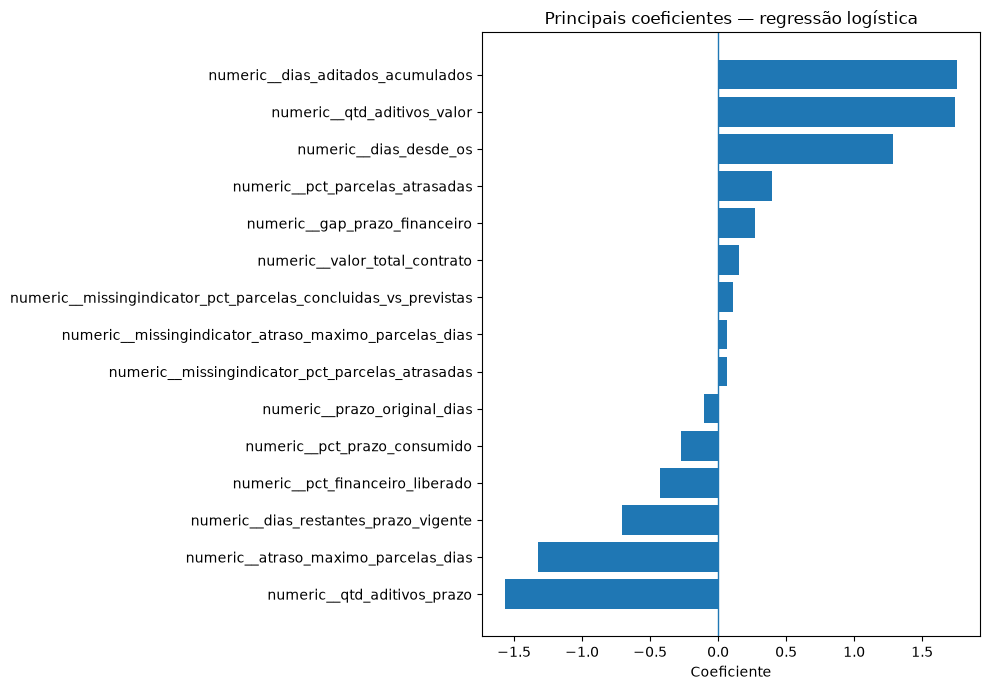

In [17]:
top = coefficient_table.head(15).sort_values("coeficiente")

plt.figure(figsize=(10, 7))
plt.barh(top["caracteristica"], top["coeficiente"])
plt.axvline(0, linewidth=1)
plt.title("Principais coeficientes — regressão logística")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()


## 8. Sanity checks contra leakage e contaminação entre splits

As verificações abaixo asseguram que:

- cada contrato rotulado pertence a apenas um split;
- features proibidas não entraram no modelo;
- o conjunto principal de classificação não contém snapshots após o vencimento do prazo.


In [18]:
# Contratos não podem aparecer em mais de um split supervisionado.
contract_splits = (
    model_data.groupby("id_contrato")["split_modelagem"]
    .nunique()
)
assert contract_splits.max() == 1, "Há contratos em mais de um split."

forbidden = {
    "id_contrato",
    "numero_contrato",
    "status_final_controle",
    "data_conclusao_controle",
    "data_termino_vigente_final_controle",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "sample_weight_contrato",
    "sample_weight_contrato_raw",
    "split_modelagem",
    "split_contrato_temporal",
}
assert not (set(features) & forbidden), "Feature proibida encontrada em X."
assert clf_data["dias_restantes_prazo_vigente"].ge(0).all()

print("Sanity checks concluídos com sucesso.")


Sanity checks concluídos com sucesso.


## 9. Salvamento de métricas, previsões e coeficientes

In [19]:
regression_metrics_df.to_csv(
    METRICS_DIR / "baseline_regressao_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_metrics_df.to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_threshold_050.csv",
    index=False,
    encoding="utf-8-sig",
)
pd.DataFrame([final_classification_metrics]).to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_teste_threshold_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)
threshold_table.to_csv(
    METRICS_DIR / "baseline_classificacao_thresholds_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)
horizon_metrics.to_csv(
    METRICS_DIR / "baseline_regressao_metricas_por_antecedencia.csv",
    index=False,
    encoding="utf-8-sig",
)
regression_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_regressao_previsoes_teste.csv",
    index=False,
    encoding="utf-8-sig",
)
classification_predictions.to_csv(
    PREDICTIONS_DIR / "baseline_classificacao_previsoes_teste.csv",
    index=False,
    encoding="utf-8-sig",
)
contract_level_metrics.to_csv(
    METRICS_DIR / "baseline_classificacao_metricas_por_contrato_90d.csv",
    index=False,
    encoding="utf-8-sig",
)
coefficient_table.to_csv(
    METRICS_DIR / "baseline_regressao_logistica_coeficientes.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Métricas:", METRICS_DIR)
print("Previsões:", PREDICTIONS_DIR)


Métricas: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\metrics
Previsões: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts\predictions
